# Fitness app users — 05 Ethics, privacy and cultural relevance

Eric Gomez · November 2026

The recommendation feature would process health-related and location data about real people. This notebook
measures what can be measured on the data:

1. who the data represent, and who they leave out;
2. how identifiable users are from their own records;
3. what a privacy-preserving release would cost in accuracy;
4. whether the models from `04` work equally well for every recorded group;
5. whether *Activity Level* measures what its name says.

The ethical guidelines at the end each rest on one of these measurements.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.visualization.theme import PALETTE, save_fig, set_plot_style
set_plot_style()
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

In [2]:
from src.data.fitness import AGE_LABELS, GENDERS, LOCATIONS, TIER_COLORS, TIERS, load_users
from src.ethics.fairness import disparity_summary, group_metric_table
from src.ethics.privacy import dp_error, equivalence_class_sizes, k_anonymity_report
from src.paths import INTERIM
from src.visualization.presentation import save_table

SEED = 803
users = load_users()
pred = pd.read_csv(INTERIM / '04_test_predictions.csv')
pred['age_band'] = pd.Categorical(pred['age_band'], AGE_LABELS, ordered=True)
print(f'{len(users):,} users; {len(pred):,} held-out test predictions from 04')

5,000 users; 1,000 held-out test predictions from 04


## 1. Who the data represent

In [3]:
rows = []
for col, levels in [('gender', GENDERS), ('location', LOCATIONS), ('age_band', AGE_LABELS)]:
    shares = users[col].value_counts(normalize=True).reindex(levels)
    rows.append({'attribute': col, 'recorded_as': ', '.join(levels),
                 'distribution': '; '.join(f'{k} {100 * v:.1f}%' for k, v in shares.items())})
rows.append({'attribute': 'age', 'recorded_as': 'whole years',
             'distribution': f"{users['age'].min()}-{users['age'].max()}; no user under 18 or over 59"})
for missing in ['ethnicity / iwi affiliation', 'language', 'disability or health condition', 'income or deprivation',
                'device or operating system', 'body measurements (weight, height)', 'session duration or heart rate']:
    rows.append({'attribute': missing, 'recorded_as': 'not recorded', 'distribution': '-'})
rep = pd.DataFrame(rows)
display(rep)
_ = save_table(rep, '05_representation')

,attribute,recorded_as,distribution
0,gender,"Female, Male",Female 49.2%; Male 50.8%
1,location,"Urban, Suburban, Rural",Urban 32.8%; Suburban 33.6%; Rural 33.7%
2,age_band,"18–29, 30–39, 40–49, 50–59",18–29 29.2%; 30–39 23.1%; 40–49 24.3%; 50–59 2...
3,age,whole years,18-59; no user under 18 or over 59
4,ethnicity / iwi affiliation,not recorded,-
5,language,not recorded,-
6,disability or health condition,not recorded,-
7,income or deprivation,not recorded,-
8,device or operating system,not recorded,-
9,"body measurements (weight, height)",not recorded,-


saved outputs/tables/05_representation.csv

                         attribute                recorded_as                                       distribution
                            gender               Female, Male                           Female 49.2%; Male 50.8%
                          location     Urban, Suburban, Rural           Urban 32.8%; Suburban 33.6%; Rural 33.7%
                          age_band 18–29, 30–39, 40–49, 50–59 18–29 29.2%; 30–39 23.1%; 40–49 24.3%; 50–59 23.3%
                               age                whole years                 18-59; no user under 18 or over 59
       ethnicity / iwi affiliation               not recorded                                                  -
                          language               not recorded                                                  -
    disability or health condition               not recorded                                                  -
             income or deprivation               not

### Interpretation

- **The recorded groups are balanced by construction.** Gender is 49.2% female and 50.8% male, each location
  type holds about a third of users, and ages spread evenly from 18 to 59. No real user base looks like this,
  which is another sign of simulation (`02`). Group results here say nothing about the proportions a real
  app would meet.
- **Whole populations are absent:**
  - anyone under 18 or over 59;
  - anyone outside two gender categories;
  - every ethnicity, language, disability and income level, because none of these is recorded.
- **Why that matters in Aotearoa New Zealand.** Physical-activity participation is lower among Pacific
  adults and among adults in high-deprivation areas, and both groups report more barriers to being active
  (Sport New Zealand, 2022). These are the groups a fitness feature most needs to work for, and these data
  cannot show whether it does. A model validated on this file has not been validated for them.

## 2. How identifiable users are

## DECISION — which attributes an attacker could know

Re-identification needs only attributes someone else could know:
- **Demographics.** Gender, age and the type of area a person lives in appear on most social profiles.
- **Activity totals.** Many fitness apps let users post workouts, yearly summaries and leaderboard
  positions publicly.

So the sets tested run from demographics alone (A) to the whole record (D), and include the activity values
alone (E). F and G are generalised releases: age in ten-year bands, sessions replaced by the tier, and in G
calories in 100-kcal bands. A group smaller than 5 is counted as at risk; the release standard used below is
k ≥ 10.

,quasi_identifiers,columns,classes,min_k,pct_unique,pct_below_k5
0,A. gender + age + location,"gender, age, location",252,10,0.00,0.00
1,B. A + activity tier,"gender, age, location, activity_level",756,1,0.08,10.37
2,C. A + exact sessions,"gender, age, location, app_sessions",4709,1,88.71,100.00
3,"D. A + exact sessions, distance and calories","gender, age, location, app_sessions, distance_...",4997,1,100.00,100.00
4,"E. exact sessions, distance and calories only","app_sessions, distance_km, calories",4992,1,99.80,100.00
5,F. gender + age band + location + tier,"gender, age_band, location, activity_level",72,47,0.00,0.00
6,G. F + calories in 100-kcal bands,"gender, age_band, location, activity_level, ca...",390,1,0.34,2.72


saved outputs/tables/05_k_anonymity.csv

                            quasi_identifiers                                                    columns  classes  min_k  pct_unique  pct_below_k5
                   A. gender + age + location                                      gender, age, location      252     10       0.000         0.000
                         B. A + activity tier                      gender, age, location, activity_level      756      1       0.080        10.366
                        C. A + exact sessions                        gender, age, location, app_sessions     4709      1      88.713       100.000
 D. A + exact sessions, distance and calories gender, age, location, app_sessions, distance_km, calories     4997      1     100.000       100.000
E. exact sessions, distance and calories only                        app_sessions, distance_km, calories     4992      1      99.800       100.000
       F. gender + age band + location + tier                 gender, age_ban

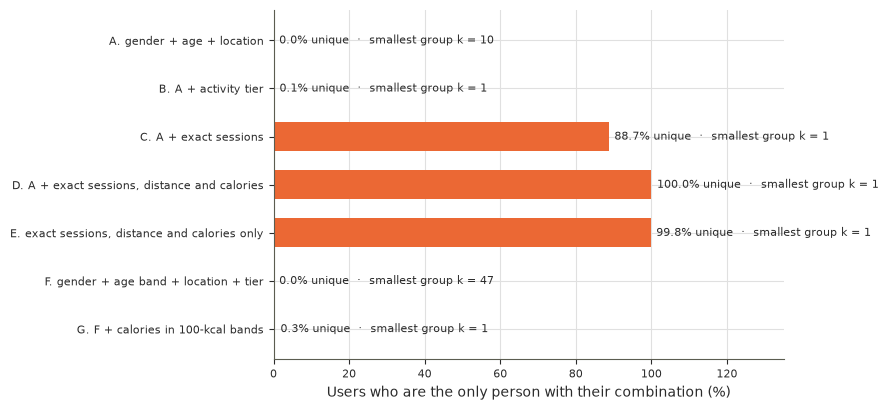

In [4]:
users['calories_band'] = pd.cut(users['calories'], range(100, 1001, 100), right=False).astype(str)
QI = {
    'A. gender + age + location': ['gender', 'age', 'location'],
    'B. A + activity tier': ['gender', 'age', 'location', 'activity_level'],
    'C. A + exact sessions': ['gender', 'age', 'location', 'app_sessions'],
    'D. A + exact sessions, distance and calories': ['gender', 'age', 'location', 'app_sessions', 'distance_km', 'calories'],
    'E. exact sessions, distance and calories only': ['app_sessions', 'distance_km', 'calories'],
    'F. gender + age band + location + tier': ['gender', 'age_band', 'location', 'activity_level'],
    'G. F + calories in 100-kcal bands': ['gender', 'age_band', 'location', 'activity_level', 'calories_band'],
}
kanon = k_anonymity_report(users.dropna(subset=['distance_km']), QI, k=5)
display(kanon.round(2))
_ = save_table(kanon.round(3), '05_k_anonymity')

fig, ax = plt.subplots(figsize=(8.6, 4.2))
y = np.arange(len(kanon))[::-1]
colours = [PALETTE['alert'] if v > 5 else PALETTE['accent'] for v in kanon['pct_below_k5']]
ax.barh(y, kanon['pct_unique'], color=colours, height=0.6)
for yi, (u, k) in zip(y, zip(kanon['pct_unique'], kanon['min_k'])):
    ax.text(u + 1.5, yi, f'{u:.1f}% unique  ·  smallest group k = {k}', va='center', fontsize=8)
ax.set_yticks(y, kanon['quasi_identifiers'])
ax.set_xlim(0, 135); ax.set_xlabel('Users who are the only person with their combination (%)')
fig.tight_layout()
save_fig(fig, '05_A_reidentification')
plt.show()

In [5]:
# l-diversity for release F: how many distinct calorie bands does each released group contain?
F = QI['F. gender + age band + location + tier']
div = users.groupby(F, observed=True)['calories_band'].nunique()
print(f'release F: {len(div)} groups; distinct calorie bands per group: min {div.min()}, median {div.median():.0f}')

release F: 72 groups; distinct calorie bands per group: min 4, median 5


### Interpretation

- **Demographics alone are safe here.** Every combination of gender, age and location type is shared by at
  least 10 users (A).
- **One more attribute breaks that.** Adding the tier leaves 10.4% of users in groups smaller than 5, and four
  users alone (B).
- **Exact activity values are a fingerprint.**
  - With exact sessions, 88.7% of users are unique (C); with the whole record, 100% (D).
  - Even with no demographics at all, exact sessions, distance and calories single out 99.8% of users (E).
  - The pattern matches the literature: a few ordinary attributes identify most people (Sweeney, 2002), and
    four points of location data identify 95% of people in a mobility dataset (de Montjoye et al., 2013).
- **Removing the user ID is therefore not anonymisation.** An "anonymous" export of exact values would let
  anyone who knows a user's yearly totals find the rest of that user's record.
- **Generalisation restores safety.** Ten-year age bands, with the tier in place of exact sessions, give 72
  groups of at least 47 users each (F). Every group contains at least four calorie bands, so membership does
  not reveal a user's calories (l-diversity ≥ 4; Machanavajjhala et al., 2007).
- **Every added field must be re-checked.** Adding calories in 100-kcal bands to F leaves 17 users (0.3%)
  unique (G).

## 3. What a private release costs: differential privacy

In [6]:
LOW, HIGH = 0, 1000                  # public bound: calories cannot exceed 5 kcal x 199 sessions = 995
EPS = [0.1, 0.5, 1.0, 2.0, 5.0]
by_loc = pd.concat([dp_error(users.loc[users['location'] == l, 'calories'], LOW, HIGH, EPS, B=2000, seed=SEED)
                    .assign(group=l) for l in LOCATIONS])
cells = users.groupby(['gender', 'location', 'age_band'], observed=True)['calories']
smallest = cells.size().idxmin()
small = dp_error(cells.get_group(smallest), LOW, HIGH, EPS, B=2000, seed=SEED).assign(group=' / '.join(smallest))
dp = pd.concat([by_loc, small])[['group', 'n', 'epsilon', 'true_mean', 'mean_abs_error', 'p95_abs_error']]
dp['p95_error_pct_of_mean'] = 100 * dp['p95_abs_error'] / dp['true_mean']
display(dp.round(2))
print('smallest gender x location x age-band cell:', smallest, 'n =', cells.size().min())
_ = save_table(dp.round(3), '05_dp_error')

,group,n,epsilon,true_mean,mean_abs_error,p95_abs_error,p95_error_pct_of_mean
0,Urban,1638,0.1,434.97,6.30,19.14,4.40
1,Urban,1638,0.5,434.97,1.21,3.52,0.81
2,Urban,1638,1.0,434.97,0.63,1.83,0.42
3,Urban,1638,2.0,434.97,0.30,0.88,0.20
4,Urban,1638,5.0,434.97,0.12,0.35,0.08
0,Suburban,1678,0.1,425.94,6.15,18.68,4.39
1,Suburban,1678,0.5,425.94,1.18,3.44,0.81
2,Suburban,1678,1.0,425.94,0.61,1.79,0.42
3,Suburban,1678,2.0,425.94,0.29,0.86,0.20
4,Suburban,1678,5.0,425.94,0.12,0.34,0.08


smallest gender x location x age-band cell: ('Female', 'Rural', '30–39') n = 176
saved outputs/tables/05_dp_error.csv

                 group    n  epsilon  true_mean  mean_abs_error  p95_abs_error  p95_error_pct_of_mean
                 Urban 1638      0.1    434.973           6.298         19.137                  4.400
                 Urban 1638      0.5    434.973           1.210          3.522                  0.810
                 Urban 1638      1.0    434.973           0.627          1.834                  0.422
                 Urban 1638      2.0    434.973           0.302          0.882                  0.203
                 Urban 1638      5.0    434.973           0.119          0.349                  0.080
              Suburban 1678      0.1    425.940           6.147         18.681                  4.386
              Suburban 1678      0.5    425.940           1.181          3.438                  0.807
              Suburban 1678      1.0    425.940           0.612  

### Interpretation

- **For large groups, differential privacy is almost free.** The mean calories of each location type (about
  1,650 users each) can be published at ε = 1 with a 95th-percentile error of 1.8 kcal, 0.4% of the mean
  (Dwork & Roth, 2014).
- **Small groups pay for it.** The smallest gender × location × age-band cell (176 rural women aged 30–39) has
  a 95th-percentile error of 17 kcal (3.9%) at ε = 1, and 178 kcal (40%) at ε = 0.1, which would make the
  figure useless.
- **Decision for any public dashboard (G6).** Release aggregates only: ε = 1 per statistic, with cells of fewer
  than 200 users merged or suppressed. Each published statistic spends part of the privacy budget. Budgets
  add up across statistics about the same users (sequential composition) but not across disjoint groups such
  as the three locations (parallel composition; Dwork & Roth, 2014). So the total is capped in advance, at
  ε = 3 per user per year (for example three statistics at ε = 1), a ledger records every release, and a
  release that would exceed the cap is refused.

## 4. Do the models work equally well for every recorded group?

Calorie error (M1), tier accuracy (M2) and the share of Sedentary users found at the default threshold, on the 1,000 held-out users from `04`.

,metric,attribute,group,n,value,ci_low,ci_high
0,calorie_mae,gender,Female,494,90.271,84.528,96.163
1,calorie_mae,gender,Male,506,92.833,86.732,98.640
2,tier_accuracy,gender,Female,494,0.794,0.757,0.828
3,tier_accuracy,gender,Male,506,0.779,0.745,0.816
4,sedentary_recall,gender,Female,154,0.922,0.877,0.961
5,sedentary_recall,gender,Male,173,0.873,0.821,0.925
6,calorie_mae,location,Rural,342,90.257,83.338,98.031
7,calorie_mae,location,Suburban,330,89.552,82.890,96.676
8,calorie_mae,location,Urban,328,94.962,87.685,102.489
9,tier_accuracy,location,Rural,342,0.792,0.749,0.836


,metric,attribute,groups,min,max,gap,ratio,all_intervals_overlap
0,calorie_mae,gender,2,90.271,92.833,2.562,1.028,True
1,tier_accuracy,gender,2,0.779,0.794,0.015,1.019,True
2,sedentary_recall,gender,2,0.873,0.922,0.049,1.056,True
3,calorie_mae,location,3,89.552,94.962,5.410,1.060,True
4,tier_accuracy,location,3,0.736,0.829,0.093,1.126,False
5,sedentary_recall,location,3,0.830,0.936,0.106,1.128,True
6,calorie_mae,age_band,4,85.168,98.811,13.643,1.160,True
7,tier_accuracy,age_band,4,0.757,0.826,0.069,1.091,True
8,sedentary_recall,age_band,4,0.855,0.924,0.068,1.080,True


saved outputs/tables/05_fairness_by_group.csv

          metric attribute    group   n   value  ci_low  ci_high
     calorie_mae    gender   Female 494 90.2712 84.5279  96.1635
     calorie_mae    gender     Male 506 92.8330 86.7320  98.6403
   tier_accuracy    gender   Female 494  0.7935  0.7570   0.8279
   tier_accuracy    gender     Male 506  0.7787  0.7451   0.8162
sedentary_recall    gender   Female 154  0.9221  0.8766   0.9610
sedentary_recall    gender     Male 173  0.8728  0.8208   0.9249
     calorie_mae  location    Rural 342 90.2574 83.3377  98.0309
     calorie_mae  location Suburban 330 89.5516 82.8899  96.6760
     calorie_mae  location    Urban 328 94.9616 87.6846 102.4887
   tier_accuracy  location    Rural 342  0.7924  0.7485   0.8363
   tier_accuracy  location Suburban 330  0.7364  0.6879   0.7848
   tier_accuracy  location    Urban 328  0.8293  0.7865   0.8689
sedentary_recall  location    Rural 105  0.9238  0.8667   0.9714
sedentary_recall  location Suburban 112  0.

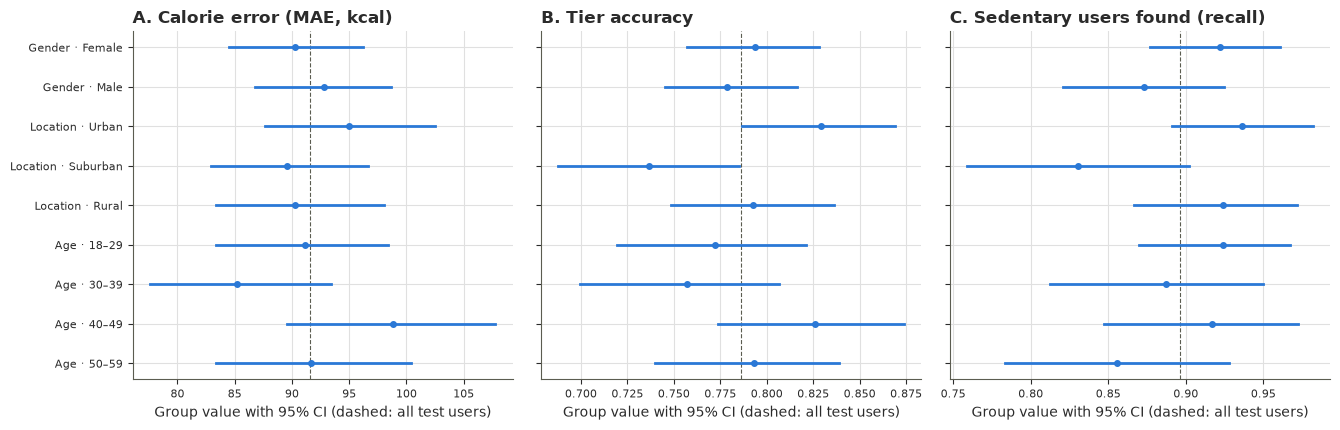

In [7]:
mae = lambda t, p: float(np.mean(np.abs(np.asarray(t) - np.asarray(p))))
acc = lambda t, p: float(np.mean(np.asarray(t) == np.asarray(p)))
pred['is_sed'] = (pred['activity_level'] == 'Sedentary')
pred['flag_sed'] = (pred['p_sedentary'] >= 0.5)

tables, summaries = [], []
for attr in ['gender', 'location', 'age_band']:
    t1 = group_metric_table(pred, attr, 'calories', 'calories_pred', mae, 'calorie_mae', B=2000, seed=SEED)
    t2 = group_metric_table(pred, attr, 'activity_level', 'tier_pred', acc, 'tier_accuracy', B=2000, seed=SEED)
    sed = pred[pred['is_sed']]
    t3 = group_metric_table(sed, attr, 'is_sed', 'flag_sed', acc, 'sedentary_recall', B=2000, seed=SEED)
    for t, name in [(t1, 'calorie_mae'), (t2, 'tier_accuracy'), (t3, 'sedentary_recall')]:
        tables.append(t.assign(metric=name).rename(columns={name: 'value'}))
        summaries.append({**disparity_summary(t, name), 'metric': name})
fair = pd.concat(tables, ignore_index=True)[['metric', 'attribute', 'group', 'n', 'value', 'ci_low', 'ci_high']]
gaps = pd.DataFrame(summaries)[['metric', 'attribute', 'groups', 'min', 'max', 'gap', 'ratio', 'all_intervals_overlap']]
display(fair.round(3))
display(gaps.round(3))
_ = save_table(fair.round(4), '05_fairness_by_group')
_ = save_table(gaps.round(4), '05_fairness_gaps')

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4), sharey=True)
order = [(a, g) for a, levels in [('gender', GENDERS), ('location', LOCATIONS), ('age_band', AGE_LABELS)] for g in levels]
label = {'gender': 'Gender', 'location': 'Location', 'age_band': 'Age'}
ypos = {f'{label[a]} · {g}': i for i, (a, g) in enumerate(order[::-1])}
titles = {'calorie_mae': 'A. Calorie error (MAE, kcal)', 'tier_accuracy': 'B. Tier accuracy',
          'sedentary_recall': 'C. Sedentary users found (recall)'}
for ax, metric in zip(axes, ['calorie_mae', 'tier_accuracy', 'sedentary_recall']):
    part = fair[fair['metric'] == metric]
    overall = {'calorie_mae': mae(pred['calories'], pred['calories_pred']),
               'tier_accuracy': acc(pred['activity_level'], pred['tier_pred']),
               'sedentary_recall': pred.loc[pred['is_sed'], 'flag_sed'].mean()}[metric]
    ax.axvline(overall, color=PALETTE['rule'], ls='--', lw=0.8)
    for r in part.itertuples():
        yv = ypos[f'{label[r.attribute]} · {r.group}']
        ax.plot([r.ci_low, r.ci_high], [yv, yv], color=PALETTE['accent'], lw=2)
        ax.plot(r.value, yv, 'o', color=PALETTE['accent'], ms=4)
    ax.set_title(titles[metric]); ax.set_xlabel('Group value with 95% CI (dashed: all test users)')
axes[0].set_yticks(list(ypos.values()), list(ypos.keys()))
fig.tight_layout()
save_fig(fig, '05_B_fairness')
plt.show()

### Interpretation

These are the shipped models from `04`: calories from sessions, and the tier from distance and calories only.
Neither model reads gender, age or location.

- **Most gaps are inside the noise.**
  - **Calorie error** (MAE) differs by 2.6 kcal between genders, 5.4 kcal across locations and 13.6 kcal across
    age bands, and every pair of intervals overlaps.
  - **Tier accuracy** differs by 1.5 points between genders and 6.9 points across age bands, again with
    overlapping intervals.
  - **Sedentary recall** differs by 4.9 points between genders, 6.9 across age bands and 10.6 across
    locations (83% Suburban, 94% Urban), with overlapping intervals.
- **One gap stands out.** Tier accuracy is 73.6% for Suburban users (95% CI 68.8–78.5) and 82.9% for Urban
  users (78.7–86.9). Those intervals do not overlap, and a χ² test across the three locations gives p = 0.014.
  Before reporting this as bias, the next cell checks where it comes from.

In [8]:
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The same split as 04.
data = users.dropna(subset=['distance_km']).reset_index(drop=True)
train, test = train_test_split(data, test_size=0.2, stratify=data['activity_level'], random_state=SEED)
CAT, NUM = ['gender', 'location'], ['distance_km', 'calories', 'age']
y_tr = train['activity_level'].astype(str)
full = Pipeline([('prep', ColumnTransformer([('num', StandardScaler(), NUM), ('cat', OneHotEncoder(drop='first'), CAT)])),
                 ('model', LogisticRegression(max_iter=2000))]).fit(train[NUM + CAT], y_tr)
blind = Pipeline([('prep', StandardScaler()), ('model', LogisticRegression(max_iter=2000))]).fit(
    train[['distance_km', 'calories']], y_tr)

def sedentary_recall(p_sed, frame):
    s = frame.assign(flag=p_sed >= 0.5)
    s = s[s['activity_level'] == 'Sedentary']
    return s, s.groupby('location', observed=True)['flag'].mean()

p_full = full.predict_proba(test[NUM + CAT])[:, list(full.classes_).index('Sedentary')]
p_blind = blind.predict_proba(test[['distance_km', 'calories']])[:, list(blind.classes_).index('Sedentary')]
# Out-of-fold predictions from the shipped model (distance and calories only, chosen in 04).
oof = cross_val_predict(blind, train[['distance_km', 'calories']], y_tr, method='predict_proba',
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
tr_sed, tr_recall = sedentary_recall(oof[:, sorted(y_tr.unique()).index('Sedentary')], train)
check = pd.DataFrame({
    'test set, shipped model (no demographics)': sedentary_recall(p_blind, test)[1],
    'test set, variant with demographics': sedentary_recall(p_full, test)[1],
    'training users, shipped model out-of-fold': tr_recall,
})
display(check.round(3))
loc_coef = pd.DataFrame(full.named_steps['model'].coef_, index=full.classes_,
                        columns=full.named_steps['prep'].get_feature_names_out()).filter(like='location')
print('largest |location coefficient| in the variant with demographics:', round(float(loc_coef.abs().max().max()), 3))
table = [[int(g['flag'].sum()), int((~g['flag']).sum())] for _, g in tr_sed.groupby('location', observed=True)]
print('chi-square across locations, out-of-fold:', round(float(stats.chi2_contingency(table)[1]), 3))
print('out-of-fold Sedentary recall by gender:', tr_sed.groupby('gender', observed=True)['flag'].mean().round(3).to_dict())
# The tier-accuracy gap by location, replicated the same way.
ok = train.assign(ok=np.array(sorted(y_tr.unique()))[oof.argmax(1)] == y_tr.to_numpy())
print('out-of-fold tier accuracy by location:', ok.groupby('location', observed=True)['ok'].mean().round(3).to_dict())
table = [[int(g.sum()), int((~g).sum())] for _, g in ok.groupby('location', observed=True)['ok']]
print('chi-square across locations, tier accuracy out-of-fold:', round(float(stats.chi2_contingency(table)[1]), 3))
test_ok = test.assign(ok=blind.predict(test[['distance_km', 'calories']]) == test['activity_level'].astype(str).to_numpy())
table = [[int(g.sum()), int((~g).sum())] for _, g in test_ok.groupby('location', observed=True)['ok']]
print('chi-square across locations, tier accuracy on the test set:', round(float(stats.chi2_contingency(table)[1]), 3))
near = pred[pred['is_sed']].assign(position=lambda d: np.where(d['app_sessions'] >= 85, 'near boundary (85-99)', 'far (50-84)'))
display(near.groupby(['position', 'location'], observed=True)['flag_sed'].agg(['size', 'mean']).round(3))
_ = save_table(check.reset_index().round(4), '05_fairness_replication')

,"test set, shipped model (no demographics)","test set, variant with demographics","training users, shipped model out-of-fold"
location,,,
Urban,0.936,0.936,0.865
Suburban,0.830,0.812,0.837
Rural,0.924,0.914,0.820


largest |location coefficient| in the variant with demographics: 0.087
chi-square across locations, out-of-fold: 0.185
out-of-fold Sedentary recall by gender: {'Female': 0.83, 'Male': 0.852}
out-of-fold tier accuracy by location: {'Urban': 0.787, 'Suburban': 0.769, 'Rural': 0.769}
chi-square across locations, tier accuracy out-of-fold: 0.425
chi-square across locations, tier accuracy on the test set: 0.014


size   mean
position              location             
far (50-84)           Rural       81  0.975
                      Suburban    70  0.971
                      Urban       69  0.986
near boundary (85-99) Rural       24  0.750
                      Suburban    42  0.595
                      Urban       41  0.854

saved outputs/tables/05_fairness_replication.csv

location  test set, shipped model (no demographics)  test set, variant with demographics  training users, shipped model out-of-fold
   Urban                                     0.9364                               0.9364                                     0.8654
Suburban                                     0.8304                               0.8125                                     0.8371
   Rural                                     0.9238                               0.9143                                     0.8201


### Interpretation

- **The model's use of location cannot be the cause.** The shipped model never sees location, and it shows the
  gap. The variant with demographics shows the same pattern (81% against 94% Sedentary recall), and its largest
  location coefficient is 0.087, too small to move a prediction.
- **The gap does not replicate.** In out-of-fold predictions on the 3,997 training users, tier accuracy is
  78.7% for Urban, 76.9% for Suburban and 76.9% for Rural users (χ² p = 0.43). Sedentary recall is 86.5%,
  83.7% and 82.0% (p = 0.19), and 83.0% for women against 85.2% for men.
- **It sits where every model is uncertain.** Far from the 100-session boundary, Sedentary recall is 97–99% in
  every location. The misses are users with 85–99 sessions, and the test set happened to hold a harder Suburban
  sample of them (60% found, against 85% for Urban).
- **The lesson for the audit (G8).** With about 110–340 users per group, one test set can produce a 9-point gap
  that passes a significance test by chance, and a real gap could hide just as easily. Group metrics need
  intervals, a correction for the number of comparisons, and replication on fresh data before anyone acts on
  them. Under the G8 rule, this gap exceeds the 5-point tolerance and is significant on the test set, but it
  does not replicate, so it is logged and monitored rather than blocking a release.
- **What the audit cannot show.** "No gap" covers two gender categories, three location types and ages 18–59.
  It says nothing about ethnicity, disability, older users or gender-diverse users, who are not in the data.

## 5. Does Activity Level measure activity?

In [9]:
users['intensity_quartile'] = pd.qcut(users['kcal_per_session'], 4,
                                      labels=['Q1 lightest', 'Q2', 'Q3', 'Q4 hardest'])
lab = pd.crosstab(users['intensity_quartile'], users['activity_level'], normalize='index').round(3) * 100
display(lab)
active_p10 = users.loc[users['activity_level'] == 'Active', 'calories'].quantile(0.10)
sed_hi = (users.loc[users['activity_level'] == 'Sedentary', 'calories'] > active_p10).mean()
overlap = users[(users['activity_level'] == 'Sedentary') & (users['calories'] >
                users.loc[users['activity_level'] == 'Active', 'calories'].min())]
print(f"Sedentary users burning more than the lowest-burning 10% of Active users (> {active_p10:.0f} kcal): {100 * sed_hi:.1f}%")
print(f"Sedentary users burning more than the lowest-burning Active user: {len(overlap)} of "
      f"{(users['activity_level'] == 'Sedentary').sum()}")
_ = save_table(lab.reset_index(), '05_label_validity')

activity_level,Sedentary,Moderate,Active
intensity_quartile,,,
Q1 lightest,34.3,33.9,31.8
Q2,30.7,36.1,33.2
Q3,34.4,33.4,32.2
Q4 hardest,31.4,35.4,33.3


Sedentary users burning more than the lowest-burning 10% of Active users (> 393 kcal): 8.3%
Sedentary users burning more than the lowest-burning Active user: 474 of 1634
saved outputs/tables/05_label_validity.csv

intensity_quartile  Sedentary  Moderate  Active
       Q1 lightest       34.3      33.9    31.8
                Q2       30.7      36.1    33.2
                Q3       34.4      33.4    32.2
        Q4 hardest       31.4      35.4    33.3


### Interpretation

- **The tier ignores how hard people exercise.** In every quarter of intensity (kcal per session), from the
  lightest to the hardest, users are split almost evenly across the three tiers (31–36% each).
- **So the label can contradict the activity it is named after.** 474 of the 1,634 Sedentary users (29%)
  burned more calories than the lowest-burning Active user, and 8.3% burned more than the bottom tenth of
  Active users.
- **This is measurement bias.** *Activity Level* is a proxy that measures app use, not activity (Suresh &
  Guttag, 2021). A user who trains hard but opens the app rarely is labelled Sedentary, and could be steered
  to beginner plans or "re-engagement" nudges. The mechanism is the one behind a widely used US health
  algorithm that under-served Black patients because it used health-care cost as a proxy for health need
  (Obermeyer et al., 2019).
- **The cultural dimension.** Activity outside the app never reaches the label: kapa haka, waka ama, team
  sport, physical work, walking to work or to church. Which activities go untracked varies with culture,
  occupation and access to devices, so the label's errors are unlikely to fall evenly across groups. Wearable
  sensors themselves can also work less well for under-represented groups (Nielsen, 2020).

## Cultural relevance: what the categories assume

| Cultural factor | What these data show or miss | Risk for interpretation | Design response |
|---|---|---|---|
| Holistic models of health: Te Whare Tapa Whā (taha tinana, hinengaro, whānau, wairua; Durie, 1985) and the Pacific Fonofale model (Pulotu-Endemann, 2001) | Physical totals only; nothing on mental, family or spiritual wellbeing | "Healthy" reduced to calories and sessions | Goals the user defines; recommendations that include whānau and group activity, rest and mental wellbeing |
| Māori data sovereignty (Te Mana Raraunga, 2018; CARE principles, Carroll et al., 2020) | No ethnicity, so data about Māori cannot be identified or governed | Once ethnicity is collected, data about Māori are a taonga with collective as well as individual interests | Collect ethnicity only for a stated benefit, governed with iwi and Māori partners (Ngā Tikanga Paihere; Stats NZ, 2020) |
| Gender beyond a binary | Two categories only | Non-binary and gender-diverse users excluded or misclassified | Follow the Stats NZ (2021) gender standard: optional field, more than two options, never required for core features |
| Age | 18–59 only | Older adults (different safe intensities) and rangatahi absent; models untested for them | Age-appropriate safety rules; validate on those groups before offering the feature to them |
| Rural life | Rural users behave identically here | Real rural users face distance to facilities, terrain, weather and patchy connectivity | Offline-first design; plans that do not assume gyms, footpaths or street lighting |
| Religious and cultural calendars | No time data | Fasting periods or days of rest change when and how hard people can train | User-controlled schedules and intensity pauses |
| Body image and calorie focus | Calories are the headline number | Fitness and calorie tracking are associated with eating-disorder symptoms (Simpson & Mazzeo, 2017) | No calorie or weight-loss targets by default; opt-in only |
| Language | Not recorded | English-only content excludes | Te reo Māori and Pacific-language options; plain-language explanations |

In [10]:
guidelines = pd.DataFrame([
    ('G1', 'Requirements', 'Purpose specification and minimisation', 'Privacy Act 2020 IPP 1, 3; GDPR Art. 5(1)(b-c)',
     'Every collected field has a documented purpose; demographics are not used to personalise', 'Demographics add no predictive value (03, 04)'),
    ('G2', 'Requirements', 'Specific, revocable consent for health and location data', 'IPP 2, 3, 3A; GDPR Art. 6, 7, 9(2)(a)',
     'Separate opt-ins for location, health metrics and imported history; the user’s authorisation as the IPP 2 basis for importing history from another service; reasonable steps to notify people when history is imported from another service, subject to exceptions (IPP 3A); withdrawal stops processing', 'Health-related fields are present; M2 relies on imported history'),
    ('G3', 'Design', 'Privacy impact assessment before build', 'OPC PIA toolkit; GDPR Art. 25, 35; ISO/IEC 27701:2025',
     'A PIA signed off before development starts and revisited at each major release', 'Re-identification risk is measurable (this notebook)'),
    ('G4', 'Design', 'Cultural and community review of features', 'Te Tiriti o Waitangi; Te Mana Raraunga; Ngā Tikanga Paihere; Algorithm Charter',
     'Co-design with Māori and Pacific users; review of labels, imagery and goal framing', 'The file records no ethnicity and binary gender only'),
    ('G5', 'Implementation', 'Security by default', 'IPP 5; ISO/IEC 27001; OWASP MASVS v2.1',
     'Encryption in transit and at rest, pseudonymous IDs, least-privilege access, audit logs', 'User IDs are sequential and reversible'),
    ('G6', 'Implementation', 'Release aggregates only, generalised or noised', 'k-anonymity; differential privacy',
     'No row-level exports; k ≥ 10 with generalised fields, or differential privacy with ε ≤ 1 per statistic; total ε capped at 3 per user per year, summed across releases (sequential composition) and tracked in a ledger', '99.8% unique on exact activity values; k = 47 after generalisation'),
    ('G7', 'Testing', 'Data validation gates', 'IPP 8 (accuracy); data contracts',
     'Idempotent event IDs, duplicate checks and cross-field rules at ingestion; failures quarantined', '299 copies (5.6%) and two ×10 entry errors'),
    ('G8', 'Testing', 'Subgroup performance audit', 'ACM Code 1.4; NIST AI RMF (Measure)',
     'Error by group with intervals in every release test; a release is blocked if a group is more than 5 points below the rest in tier accuracy or Sedentary recall (or 10% above in calorie MAE), the gap is significant after the Holm correction, and it replicates out of fold or on the next data', 'A 9-point Suburban test-set gap (p = 0.014) that did not replicate out of fold (p = 0.43); unrecorded groups untested'),
    ('G9', 'Deployment', 'Transparency and user control', 'IPP 6, 7; GDPR Art. 13-15, 22',
     'Explain why each recommendation is shown; users can view, correct and export their data and override their tier', 'The tier is a rule users can be told'),
    ('G10', 'Deployment', 'Safe recommendations', 'ACM Code 1.2; Health and safety duty of care',
     'Calorie figures shown as ranges; no weight-loss targets by default; screening prompts for health conditions', 'Calorie error grows with activity (04)'),
    ('G11', 'Operation', 'Retention, deletion and breach response', 'IPP 9; Privacy Act Part 6; GDPR Art. 17, 33',
     'Retention schedule, deletion on account closure, notify the Privacy Commissioner of serious breaches', 'Copies show data can be duplicated silently'),
    ('G12', 'Operation', 'Monitoring and accountability', 'NIST AI RMF (Govern, Manage); ISO/IEC 42001',
     'Named privacy officer, drift monitors on data invariants, yearly ethics review', 'Stable invariants: 0.5-1.0 km and 2-5 kcal per session'),
], columns=['id', 'sdlc_phase', 'guideline', 'standard_or_principle', 'control', 'evidence_from_these_data'])
guidelines['check'] = [
    'Data inventory reviewed at each release: no field without a purpose',
    'Consent records audited; a withdrawal test in the QA suite',
    'PIA approved before the first sprint',
    'Review-panel record; usability tests with Māori and Pacific users',
    'Penetration test and MASVS checklist (incl. MASVS-PRIVACY) before release',
    'Automated k-anonymity (k ≥ 10) and privacy-budget tests in the release pipeline',
    'Per-batch report of duplicate rate and rule failures',
    'Fairness tests in CI, replicated on a second sample before a gap is reported',
    'Explanation present for every recommendation; export and correction work',
    'Content review of goal framing; clinical review of safety prompts',
    'Deletion test; yearly breach drill',
    'Monthly drift report; yearly ethics review',
]
_ = save_table(guidelines, '05_guidelines')

saved outputs/tables/05_guidelines.csv

 id     sdlc_phase                                                guideline                                                          standard_or_principle                                                                                                                                                                                                                                                                                                  control                                                                                              evidence_from_these_data                                                                           check
 G1   Requirements                   Purpose specification and minimisation                                 Privacy Act 2020 IPP 1, 3; GDPR Art. 5(1)(b-c)                                                                                                                                                            

## Ethical guidelines for the development process

Each guideline names its stage in the software development life cycle, the standard or principle behind it,
the control, the evidence from these data that motivates it, and how compliance is checked.

| ID | Stage | Guideline | Standard or principle | Control | Evidence here | Check |
|---|---|---|---|---|---|---|
| G1 | Requirements | Purpose specification and minimisation | Privacy Act 2020 IPP 1, 3; GDPR Art. 5(1)(b–c) | Every field has a documented purpose; demographics are not used to personalise | Demographics add no predictive value (`03`, `04`) | Data inventory reviewed at each release |
| G2 | Requirements | Specific, revocable consent for health and location data | IPP 2, 3 and 3A; GDPR Art. 6, 7, 9(2)(a) | Separate opt-ins; the user's authorisation as the IPP 2 basis for importing history from another service; reasonable steps to notify people when history is imported from another service, subject to exceptions (IPP 3A, from 1 May 2026); withdrawal stops processing | M2 relies on imported history | Consent records audited; withdrawal tested |
| G3 | Design | Privacy impact assessment before build | OPC PIA toolkit; GDPR Art. 25, 35; ISO/IEC 27701:2025 | A PIA approved before development and revisited at each major release | Re-identification risk is measurable (above) | PIA sign-off before the first sprint |
| G4 | Design | Cultural and community review | Te Tiriti o Waitangi; Te Mana Raraunga; Ngā Tikanga Paihere; Algorithm Charter | Co-design with Māori and Pacific users; review of labels, imagery and goal framing | No ethnicity recorded; binary gender only; a misleading tier label | Review record; usability tests with those users |
| G5 | Implementation | Security by default | IPP 5; ISO/IEC 27001; OWASP MASVS v2.1 | Encryption in transit and at rest, pseudonymous IDs, least-privilege access, audit logs | User IDs are sequential | Penetration test and MASVS (incl. MASVS-PRIVACY) checklist |
| G6 | Implementation | Release aggregates only, generalised or noised | k-anonymity; l-diversity; differential privacy | No row-level exports; k ≥ 10 on generalised fields, or ε ≤ 1 per statistic with small cells suppressed; total ε capped at 3 per user per year, summed across releases (sequential composition) | 99.8% unique on exact activity values; k = 47 after generalisation | Automated k and privacy-budget tests in the release pipeline |
| G7 | Testing | Data validation gates | IPP 8 (accuracy); data contracts | Idempotent event IDs; duplicate and cross-field checks at ingestion; failures quarantined | 299 copies (5.6%); two ×10 errors | Per-batch duplicate and rule-failure report |
| G8 | Testing | Subgroup performance audit | ACM Code 1.4; NIST AI RMF (Measure) | Error by group with intervals at every release. A release is blocked if a group's tier accuracy or Sedentary recall is more than 5 points below the rest (or its calorie MAE more than 10% above), the gap is significant after the Holm correction, and it replicates out of fold or on the next data | A 9-point test-set gap (p = 0.014) that did not replicate | Fairness tests in CI |
| G9 | Deployment | Transparency and user control | IPP 6, 7; GDPR Art. 13–15, 22 | Explain each recommendation; users can view, correct and export their data and override their tier | The tier is a rule users can be told | Explanation and export tests |
| G10 | Deployment | Safe recommendations | ACM Code 1.2 (avoid harm) | Calories shown as ranges; no weight-loss targets by default; prompts about health conditions | Calorie error grows with activity (`04`) | Content and clinical review |
| G11 | Operation | Retention, deletion and breach response | IPP 9; Privacy Act Part 6; GDPR Art. 17, 33 | Retention schedule; deletion on account closure; notify the Privacy Commissioner of serious breaches | Copies show data can be duplicated silently | Deletion test; yearly breach drill |
| G12 | Operation | Monitoring and accountability | NIST AI RMF (Govern, Manage); ISO/IEC 42001 | Named privacy officer; drift monitors on data invariants; yearly ethics review | Stable invariants: 0.5–1.0 km and 2–5 kcal per session | Monthly drift report |

## Dashboard

`outputs/dashboards/fitness_dashboard.html` presents these results in four views: overview, engagement, models and
ethics. It is one self-contained page that loads no outside script, so it opens offline.

It follows guideline G6 itself. It carries the results tables and one binned count of users by sessions and calories,
with any cell under five users suppressed. No row-level record reaches it. It is rebuilt here from `outputs/tables/`, so
it changes when the analysis does. Screenshots: `python -m src.visualization.dashboard --screenshot` (needs Chrome).

In [11]:
from src.visualization.dashboard import build_dashboard_html

_ = build_dashboard_html()

saved outputs/dashboards/fitness_dashboard.html (88 KB)


## References

Carroll, S. R., Garba, I., Figueroa-Rodríguez, O. L., Holbrook, J., Lovett, R., Materechera, S., Parsons, M.,
Raseroka, K., Rodriguez-Lonebear, D., Rowe, R., Sara, R., Walker, J. D., Anderson, J., & Hudson, M. (2020). The
CARE principles for Indigenous data governance. *Data Science Journal, 19*, Article 43.
https://doi.org/10.5334/dsj-2020-043

de Montjoye, Y.-A., Hidalgo, C. A., Verleysen, M., & Blondel, V. D. (2013). Unique in the crowd: The privacy
bounds of human mobility. *Scientific Reports, 3*, Article 1376. https://doi.org/10.1038/srep01376

Durie, M. H. (1985). A Maori perspective of health. *Social Science & Medicine, 20*(5), 483–486.
https://doi.org/10.1016/0277-9536(85)90363-6

Dwork, C., & Roth, A. (2014). The algorithmic foundations of differential privacy. *Foundations and Trends in
Theoretical Computer Science, 9*(3–4), 211–407. https://doi.org/10.1561/0400000042

Machanavajjhala, A., Kifer, D., Gehrke, J., & Venkitasubramaniam, M. (2007). ℓ-diversity: Privacy beyond
k-anonymity. *ACM Transactions on Knowledge Discovery from Data, 1*(1), Article 3.
https://doi.org/10.1145/1217299.1217302

Nielsen, A. (2020). *Practical fairness: Achieving fair and secure data models*. O'Reilly Media.

Obermeyer, Z., Powers, B., Vogeli, C., & Mullainathan, S. (2019). Dissecting racial bias in an algorithm used to
manage the health of populations. *Science, 366*(6464), 447–453. https://doi.org/10.1126/science.aax2342

Pulotu-Endemann, F. K. (2001). *Fonofale model of health*. https://www.hauora.co.nz/assets/Fonofalemodelexplanation.pdf

Simpson, C. C., & Mazzeo, S. E. (2017). Calorie counting and fitness tracking technology: Associations with
eating disorder symptomatology. *Eating Behaviors, 26*, 89–92. https://doi.org/10.1016/j.eatbeh.2017.02.002

Sport New Zealand. (2022). *Active NZ: Updating the participation landscape. The New Zealand Participation
Survey 2021*. https://sportnz.org.nz/resources/active-nz-updating-the-participation-landscape/

Stats NZ. (2020). *Ngā Tikanga Paihere: Guidelines*.
https://data.govt.nz/assets/data-ethics/Nga-Tikanga/Nga-Tikanga-Paihere-Guidelines-December-2020.pdf

Stats NZ. (2021). *Data standard for gender, sex, and variations of sex characteristics*.
https://www.stats.govt.nz/assets/Methods/Data-standards-for-sex-gender-and-variations-on-sex-characteristics/downloads/Data-standard-for-gender-sex-and-variations-of-sex-characteristics.pdf

Suresh, H., & Guttag, J. (2021). A framework for understanding sources of harm throughout the machine learning
life cycle. In *Equity and Access in Algorithms, Mechanisms, and Optimization (EAAMO '21)*, Article 17. ACM.
https://doi.org/10.1145/3465416.3483305

Sweeney, L. (2002). k-anonymity: A model for protecting privacy. *International Journal of Uncertainty,
Fuzziness and Knowledge-Based Systems, 10*(5), 557–570. https://doi.org/10.1142/S0218488502001648

Te Mana Raraunga. (2018). *Principles of Māori data sovereignty* (Brief No. 1).
https://www.temanararaunga.maori.nz/principles-of-maori-data-sovereignty